In [ ]:
import pandas as pd

from google.colab import files

# Fazer upload do arquivo CSV
uploaded = files.upload()

# Ler a planilha
nome_arquivo = list(uploaded.keys())[0]
df = pd.read_csv(nome_arquivo)

# Mostrar as primeiras linhas
df.head()


Saving Feedbacks_brutos - Feedbacks_Brutos.csv to Feedbacks_brutos - Feedbacks_Brutos.csv


,id_feedback,data,canal,cliente_id,feedback,sentimento_ia,categoria_ia,prioridade_ia,resumo_ia,acao_sugerida_ia,caso_critico
0,FB0001,2026-10-01 18:00:00,WhatsApp,CL2824,Meu pedido está atrasado há 8 dias e ninguém m...,Negativo,Logística,Alta,O cliente relatou que seu pedido está atrasado...,Imediatamente contate o cliente para fornecer ...,SIM
1,FB0002,2026-10-02 08:00:00,E-mail,CL5506,Recebi o produto errado. Preciso trocar o quan...,Negativo,Troca e Devolução,Alta,O cliente recebeu o produto errado e precisa t...,Imediatamente iniciar o processo de troca do p...,SIM
2,FB0003,2026-10-03 11:00:00,Reclame Aqui,CL4657,A entrega passou do prazo e o rastreamento não...,Negativo,Logística,Alta,O principal problema relatado pelo cliente é q...,Imediatamente entre em contato com o cliente p...,SIM
3,FB0004,2026-10-04 10:00:00,WhatsApp,CL2679,"Adorei o livro, chegou muito bem embalado e an...",Positivo,Elogio,Baixa,"O cliente elogiou o livro, destacando que cheg...",Agradeça ao cliente pelo feedback positivo e c...,NÃO
4,FB0005,2026-10-05 18:00:00,E-mail,CL9935,Gostaria de saber quando meu pedido será enviado.,Neutro,Logística,Baixa,O cliente gostaria de saber quando seu pedido ...,Recomendo enviar uma resposta ao cliente com a...,NÃO


In [ ]:
# Verificar quantidade de linhas e colunas
print("Dimensões da base:", df.shape)

# Verificar nomes das colunas
print("\nColunas:")
print(df.columns.tolist())

# Verificar tipos de dados
print("\nTipos de dados:")
print(df.dtypes)

# Verificar valores vazios
print("\nValores vazios:")
print(df.isnull().sum())

Dimensões da base: (60, 11)

Colunas:
['id_feedback', 'data', 'canal', 'cliente_id', 'feedback', 'sentimento_ia', 'categoria_ia', 'prioridade_ia', 'resumo_ia', 'acao_sugerida_ia', 'caso_critico']

Tipos de dados:
id_feedback         object
data                object
canal               object
cliente_id          object
feedback            object
sentimento_ia       object
categoria_ia        object
prioridade_ia       object
resumo_ia           object
acao_sugerida_ia    object
caso_critico        object
dtype: object

Valores vazios:
id_feedback         0
data                0
canal               0
cliente_id          0
feedback            0
sentimento_ia       0
categoria_ia        0
prioridade_ia       0
resumo_ia           0
acao_sugerida_ia    0
caso_critico        0
dtype: int64


In [ ]:
# Quantidade de feedbacks por sentimento
print("DISTRIBUIÇÃO DE SENTIMENTOS")
print(df["sentimento_ia"].value_counts())

# Quantidade de feedbacks por categoria
print("\nDISTRIBUIÇÃO POR CATEGORIA")
print(df["categoria_ia"].value_counts())

# Quantidade de feedbacks por prioridade
print("\nDISTRIBUIÇÃO POR PRIORIDADE")
print(df["prioridade_ia"].value_counts())

# Quantidade de casos críticos
print("\nCASOS CRÍTICOS")
print(df["caso_critico"].value_counts())

DISTRIBUIÇÃO DE SENTIMENTOS
sentimento_ia
Negativo    32
Positivo    15
Neutro      13
Name: count, dtype: int64

DISTRIBUIÇÃO POR CATEGORIA
categoria_ia
Logística               19
Elogio                  11
Troca e Devolução        7
Financeiro               7
Atendimento              5
Qualidade do Produto     5
Tecnologia               5
Outros                   1
Name: count, dtype: int64

DISTRIBUIÇÃO POR PRIORIDADE
prioridade_ia
Baixa      25
Alta       22
Crítica    10
Média       3
Name: count, dtype: int64

CASOS CRÍTICOS
caso_critico
SIM    31
NÃO    29
Name: count, dtype: int64


In [ ]:
# Cruzar sentimento e prioridade
print("SENTIMENTO X PRIORIDADE")

print(pd.crosstab(
    df["sentimento_ia"],
    df["prioridade_ia"]
))

# Recalcular a regra de casos críticos no Python
regra_critica = (
    (df["sentimento_ia"] == "Negativo") &
    (df["prioridade_ia"].isin(["Alta", "Crítica"]))
)

# Comparar com a coluna criada no Google Sheets
divergencias = df[
    regra_critica != (df["caso_critico"] == "SIM")
]

print("\nQUANTIDADE DE DIVERGÊNCIAS:")
print(len(divergencias))

print("\nREGISTROS COM DIVERGÊNCIAS:")
display(divergencias[
    ["id_feedback", "sentimento_ia",
     "prioridade_ia", "caso_critico"]
])

SENTIMENTO X PRIORIDADE
prioridade_ia  Alta  Baixa  Crítica  Média
sentimento_ia                             
Negativo         21      0       10      1
Neutro            1     10        0      2
Positivo          0     15        0      0

QUANTIDADE DE DIVERGÊNCIAS:
0

REGISTROS COM DIVERGÊNCIAS:


,id_feedback,sentimento_ia,prioridade_ia,caso_critico


In [ ]:
# Cruzar categoria e sentimento
analise_categoria = pd.crosstab(
    df["categoria_ia"],
    df["sentimento_ia"]
)

# Ordenar pelas categorias com mais feedbacks negativos
analise_categoria = analise_categoria.sort_values(
    by="Negativo",
    ascending=False
)

print("FEEDBACKS POR CATEGORIA E SENTIMENTO")
display(analise_categoria)

FEEDBACKS POR CATEGORIA E SENTIMENTO


sentimento_ia,Negativo,Neutro,Positivo
categoria_ia,,,
Logística,12,7,0
Tecnologia,5,0,0
Qualidade do Produto,4,0,1
Financeiro,4,2,1
Troca e Devolução,4,3,0
Atendimento,3,0,2
Elogio,0,0,11
Outros,0,1,0


In [ ]:
# Criar tabela com a quantidade de feedbacks por categoria
analise_percentual = pd.crosstab(
    df["categoria_ia"],
    df["sentimento_ia"],
    normalize="index"
) * 100

# Arredondar os percentuais para duas casas decimais
analise_percentual = analise_percentual.round(2)

print("PERCENTUAL DE SENTIMENTOS POR CATEGORIA")
display(analise_percentual)

PERCENTUAL DE SENTIMENTOS POR CATEGORIA


sentimento_ia,Negativo,Neutro,Positivo
categoria_ia,,,
Atendimento,60.00,0.00,40.00
Elogio,0.00,0.00,100.00
Financeiro,57.14,28.57,14.29
Logística,63.16,36.84,0.00
Outros,0.00,100.00,0.00
Qualidade do Produto,80.00,0.00,20.00
Tecnologia,100.00,0.00,0.00
Troca e Devolução,57.14,42.86,0.00


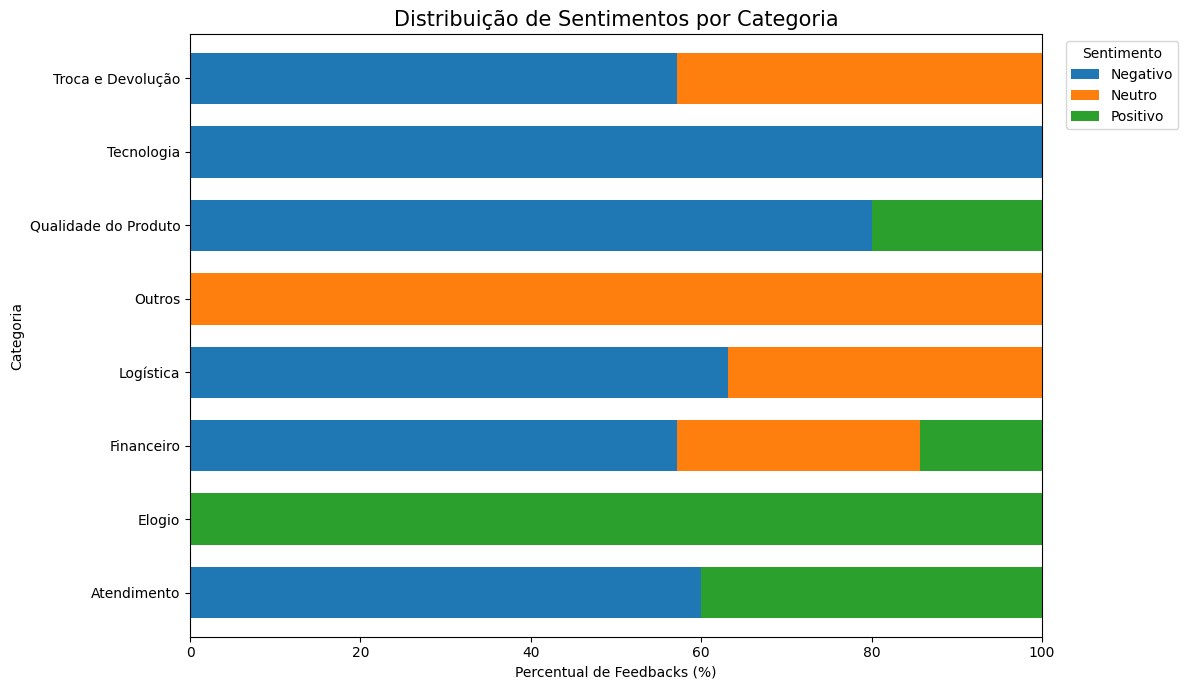

In [ ]:
import matplotlib.pyplot as plt

# Criar tabela de percentuais
grafico = pd.crosstab(
    df["categoria_ia"],
    df["sentimento_ia"],
    normalize="index"
) * 100

# Criar gráfico de barras empilhadas
grafico = grafico[["Negativo", "Neutro", "Positivo"]]

grafico.plot(
    kind="barh",
    stacked=True,
    figsize=(12, 7),
    width=0.7
)

plt.title(
    "Distribuição de Sentimentos por Categoria",
    fontsize=15
)

plt.xlabel("Percentual de Feedbacks (%)")
plt.ylabel("Categoria")

plt.xlim(0, 100)
plt.legend(title="Sentimento", bbox_to_anchor=(1.02, 1))
plt.tight_layout()

plt.show()

In [ ]:
# Total de feedbacks
total_feedbacks = len(df)

# Quantidade de feedbacks negativos
feedbacks_negativos = (
    df["sentimento_ia"] == "Negativo"
).sum()

# Quantidade de casos críticos
casos_criticos = (
    df["caso_critico"] == "SIM"
).sum()

# Calcular os percentuais
taxa_negativos = (
    feedbacks_negativos / total_feedbacks
) * 100

taxa_criticos = (
    casos_criticos / total_feedbacks
) * 100

# Exibir os KPIs
print("INDICADORES DE CUSTOMER EXPERIENCE")
print("-----------------------------------")
print(f"Total de feedbacks: {total_feedbacks}")
print(f"Feedbacks negativos: {feedbacks_negativos}")
print(f"Taxa de feedbacks negativos: {taxa_negativos:.2f}%")
print(f"Casos críticos: {casos_criticos}")
print(f"Taxa de casos críticos: {taxa_criticos:.2f}%")

INDICADORES DE CUSTOMER EXPERIENCE
-----------------------------------
Total de feedbacks: 60
Feedbacks negativos: 32
Taxa de feedbacks negativos: 53.33%
Casos críticos: 31
Taxa de casos críticos: 51.67%


In [ ]:
# Quantidade de feedbacks por canal
analise_canais = pd.crosstab(
    df["canal"],
    df["sentimento_ia"]
)

# Adicionar o total de feedbacks por canal
analise_canais["Total"] = analise_canais.sum(axis=1)

# Calcular percentual negativo por canal
analise_canais["Taxa_negativa_%"] = (
    analise_canais["Negativo"] /
    analise_canais["Total"]
) * 100

# Arredondar percentuais
analise_canais["Taxa_negativa_%"] = (
    analise_canais["Taxa_negativa_%"].round(2)
)

print("ANÁLISE DE FEEDBACKS POR CANAL")
display(analise_canais)

ANÁLISE DE FEEDBACKS POR CANAL


sentimento_ia,Negativo,Neutro,Positivo,Total,Taxa_negativa_%
canal,,,,,
E-mail,9,6,8,23,39.13
Reclame Aqui,13,0,0,13,100.00
WhatsApp,10,7,7,24,41.67


In [ ]:
# Criar uma cópia da base original
df_powerbi = df.copy()

# Conferir registros duplicados
duplicados = df_powerbi.duplicated(
    subset=["id_feedback"]
).sum()

print("REGISTROS DUPLICADOS:", duplicados)

# Conferir se existem valores vazios
print("\nVALORES VAZIOS:")
print(df_powerbi.isnull().sum())

# Conferir quantidade de registros
print("\nTOTAL DE REGISTROS:", len(df_powerbi))

# Exportar base para CSV
df_powerbi.to_csv(
    "feedbacks_cx_powerbi.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nArquivo exportado com sucesso!")

REGISTROS DUPLICADOS: 0

VALORES VAZIOS:
id_feedback         0
data                0
canal               0
cliente_id          0
feedback            0
sentimento_ia       0
categoria_ia        0
prioridade_ia       0
resumo_ia           0
acao_sugerida_ia    0
caso_critico        0
dtype: int64

TOTAL DE REGISTROS: 60

Arquivo exportado com sucesso!


In [ ]:
from google.colab import files

files.download("feedbacks_cx_powerbi.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>